[**DISCLAIMER**]
The dataset used is downloaded from https://www.kaggle.com/datasets/janiobachmann/bank-marketing-dataset/data which in turn has given credit to [Moro et al., 2014] S. Moro, P. Cortez and P. Rita. A Data-Driven Approach to Predict the Success of Bank Telemarketing. Decision Support Systems, Elsevier, 62:22-31, June 2014

In [ ]:
#import file bank.csv into pandas df

import pandas as pd

df = pd.read_csv('bank.csv')
# Encode deposit subscription as booleans: yes -> True, no -> False.
df['deposit'] = df['deposit'].map({'yes': True, 'no': False})
df
    

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,True
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,True
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,True
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,True
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11157,33,blue-collar,single,primary,no,1,yes,no,cellular,20,apr,257,1,-1,0,unknown,False
11158,39,services,married,secondary,no,733,no,no,unknown,16,jun,83,4,-1,0,unknown,False
11159,32,technician,single,secondary,no,29,no,no,cellular,19,aug,156,2,-1,0,unknown,False
11160,43,technician,married,secondary,no,0,no,yes,cellular,8,may,9,2,172,5,failure,False


In [4]:
# Check the target class distribution (deposit subscription).
target = df['deposit']
class_counts = target.value_counts().rename_axis('deposit')
class_distribution = class_counts.to_frame(name='count')
class_distribution['percentage'] = (class_counts / class_counts.sum() * 100).round(2)

print(f"Missing target values: {target.isna().sum():,}")
class_distribution

Missing target values: 0


,count,percentage
deposit,,
False,5873,52.62
True,5289,47.38


In [5]:
# Quantify imbalance among the observed, non-missing classes.
majority_class = class_counts.idxmax()
majority_baseline = class_counts.max() / class_counts.sum()

if len(class_counts) > 1:
    imbalance_ratio = class_counts.max() / class_counts.min()
    print(f"Majority-to-minority class ratio: {imbalance_ratio:.2f}:1 (1:1 is balanced)")
else:
    print("Only one observed class; a class imbalance ratio is not defined.")

print(f"Majority-class accuracy baseline (always predict '{majority_class}'): {majority_baseline:.2%}")

Majority-to-minority class ratio: 1.11:1 (1:1 is balanced)
Majority-class accuracy baseline (always predict 'False'): 52.62%


### Feature distributions

Inspect numeric histograms over the full observed range and categorical count plots. The target `deposit` is excluded.

In [6]:
import matplotlib.pyplot as plt

features = df.drop(columns='deposit')
numeric_features = features.select_dtypes(include='number')

numeric_summary = numeric_features.describe().T[['min', '25%', '50%', '75%', 'max']]
numeric_summary = numeric_summary.rename(columns={'50%': 'median'})
numeric_summary['skewness'] = numeric_features.skew()
numeric_summary['missing'] = numeric_features.isna().sum()
numeric_summary.round(2)

,min,25%,median,75%,max,skewness,missing
age,18.0,32.0,39.0,49.00,95.0,0.86,0
balance,-6847.0,122.0,550.0,1708.00,81204.0,8.22,0
day,1.0,8.0,15.0,22.00,31.0,0.11,0
duration,2.0,138.0,255.0,496.00,3881.0,2.14,0
campaign,1.0,1.0,2.0,3.00,63.0,5.55,0
pdays,-1.0,-1.0,-1.0,20.75,854.0,2.45,0
previous,0.0,0.0,0.0,1.00,58.0,7.34,0


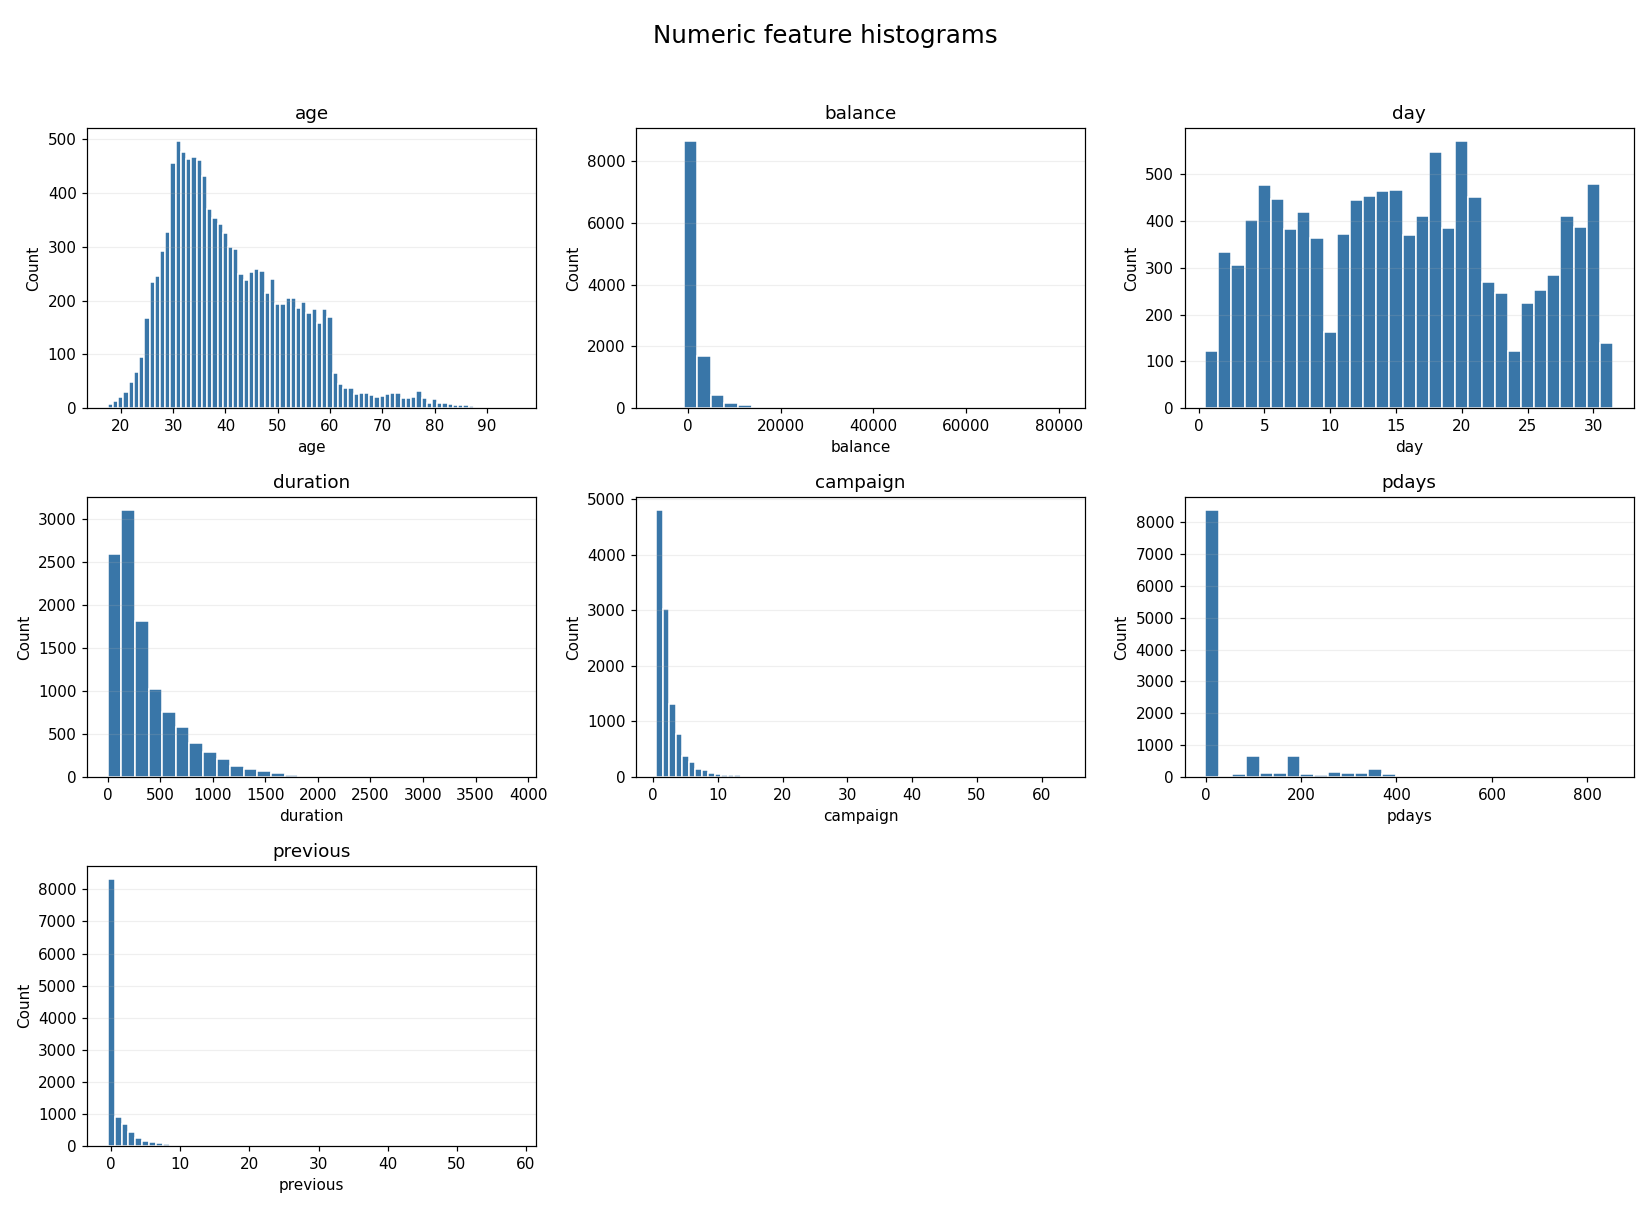

In [7]:
# Keep the full range so long tails and unusual values remain visible.
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, column in zip(axes.flat, numeric_features.columns):
    values = numeric_features[column].dropna()
    # Center bins on integers for age, day, and contact counts.
    bins = ([value - 0.5 for value in range(int(values.min()), int(values.max()) + 2)]
            if column in ['age', 'day', 'campaign', 'previous'] else 30)
    ax.hist(values, bins=bins, color='#3976a8', edgecolor='white')
    ax.set_title(column)
    ax.set_xlabel(column)
    ax.set_ylabel('Count')
    ax.grid(axis='y', alpha=0.2)

for ax in axes.flat[len(numeric_features.columns):]:
    ax.set_visible(False)

fig.suptitle('Numeric feature histograms', fontsize=16)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

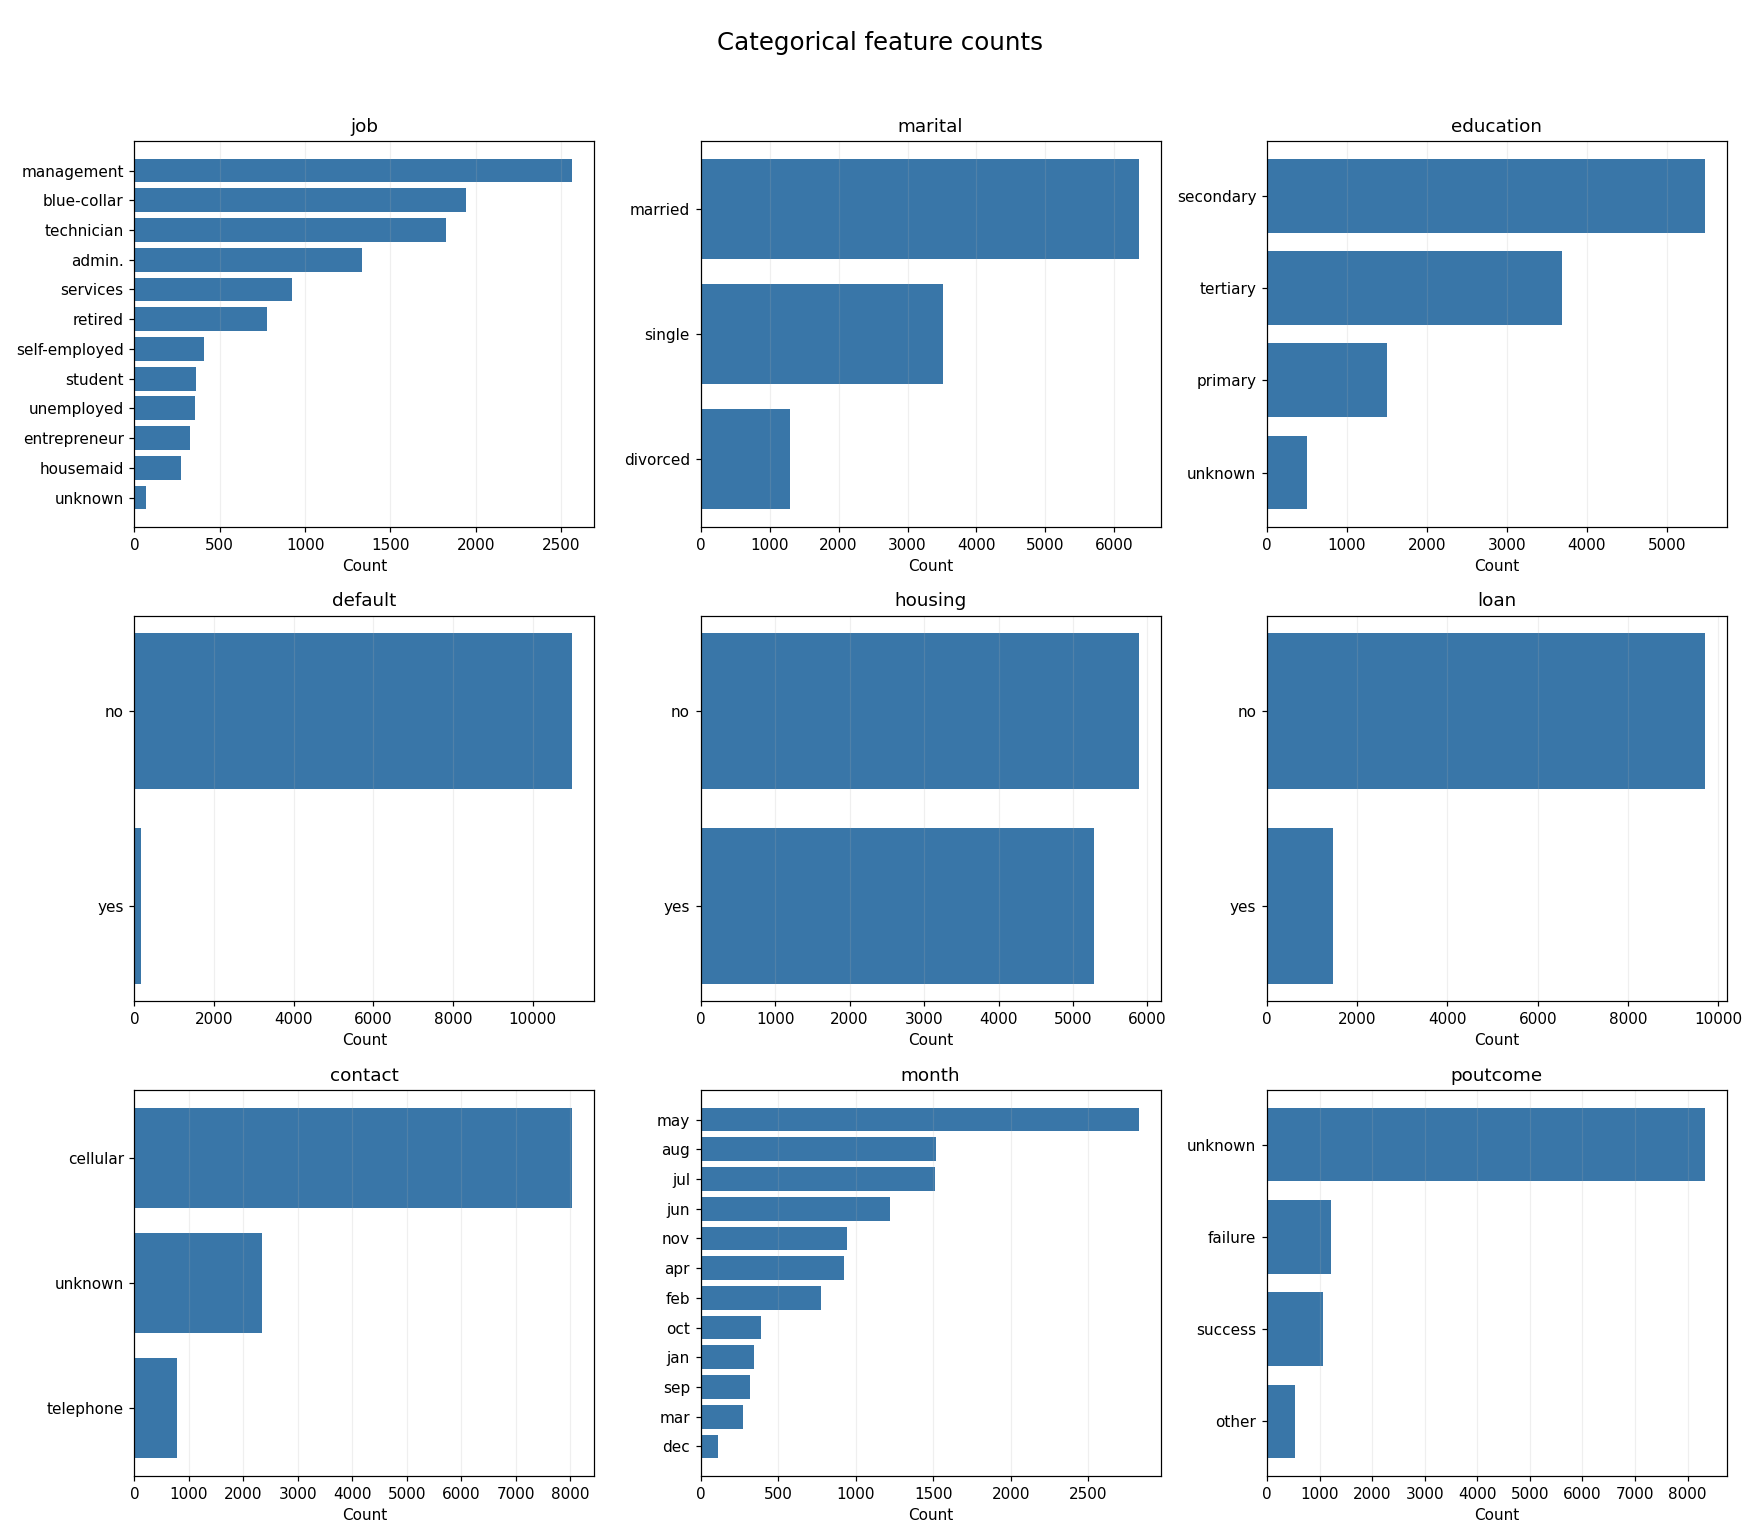

In [8]:
# Use category counts for nonnumeric features, including "unknown" values.
categorical_features = features.select_dtypes(exclude='number')
fig, axes = plt.subplots(3, 3, figsize=(16, 14))
for ax, column in zip(axes.flat, categorical_features.columns):
    counts = categorical_features[column].value_counts(dropna=False).sort_values()
    ax.barh(counts.index.astype(str), counts.values, color='#3976a8')
    ax.set_title(column)
    ax.set_xlabel('Count')
    ax.grid(axis='x', alpha=0.2)

for ax in axes.flat[len(categorical_features.columns):]:
    ax.set_visible(False)

fig.suptitle('Categorical feature counts', fontsize=16)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

**Observations from this dataset**

- `balance`, `duration`, `campaign`, `pdays`, and `previous` have long right tails. `balance` ranges from -6,847 to 81,204, with a median of 550; investigate extremes before deciding on transformations.
- `pdays` is -1 for 8,324 rows (74.57%), and `previous` is zero for the same rows. Treat the -1 spike separately when interpreting the `pdays` distribution.
- `age` has a moderate right tail; `day` has relatively little skew.
- Categorical features can be concentrated even with a balanced target: `default` is overwhelmingly "no", and `poutcome` is mostly "unknown". There are no missing numeric values.

These plots preserve the original data; no rows are removed or values transformed.

### Prior-contact flag

Added `previously_contacted`: 1 when `pdays != -1`, otherwise 0. `pdays = -1` means no previous contact, so the flag distinguishes that group from actual elapsed days. The original `pdays` column is retained.

In [ ]:
df['previously_contacted'] = df['pdays'].ne(-1).astype('int8')

### Drop call length

Dropped `duration` because we do not know the call length before the call happens. This avoids using information unavailable when making a prediction.

In [ ]:
df = df.drop(columns='duration')
features = df.drop(columns='deposit')

### Outlier decisions before scaling

**Keep all 11,162 rows, with no log transforms or clipping.** We found no confirmed errors that justify deletion. The record review and validation comparison below support retaining rare customers. `features` keeps the original numeric magnitudes; its only recoding is the `pdays` placeholder. Earlier plots describe the values before that recoding.

| Feature | Decision | Brief reason |
| --- | --- | --- |
| `age` | Keep 18–95 unchanged. | No severe IQR flags; the oldest customers are retired, consistent with their ages. |
| `job` | Keep every category, including `unknown`. | Rare occupations are valid groups; unknown records missing information. |
| `marital` | Keep every category. | All observed marital-status categories are valid. |
| `education` | Keep every category, including `unknown`. | Less common levels and missing-information labels are not data errors. |
| `default` | Keep both values. | The 168 defaults are rare but describe a meaningful credit condition. |
| `balance` | Keep −6,847 to 81,204 unchanged. | Debt and high savings are plausible; reviewed extremes have coherent accompanying attributes. |
| `housing` | Keep both values. | Having or not having a housing loan is valid. |
| `loan` | Keep both values. | Personal-loan status is a valid binary feature. |
| `contact` | Keep every category, including `unknown`. | Telephone contacts and missing channel information are valid groups. |
| `day` | Keep 1–31 unchanged. | All values are valid day-of-month numbers. |
| `month` | Keep every month. | Uneven counts can reflect campaign scheduling, not erroneous months. |
| `campaign` | Keep 1–63 unchanged. | Repeated outreach is documented; there is no verified maximum that makes these counts invalid. |
| `pdays` | Keep actual elapsed days (1–854); use 0 for the −1 sentinel in `features`. | Long gaps are plausible; `previously_contacted` identifies the placeholder as no prior contact. |
| `previous` | Keep 0–58 unchanged. | Zero is structural no-history; positive counts require separate review, with no confirmed errors. |
| `poutcome` | Keep every category, including `unknown` and `other`. | These are valid outcome labels; unknown does not always mean no prior contact. |
| `previously_contacted` | Keep 0/1 unchanged. | This flag distinguishes no history from observed elapsed days. |

**Why we did not delete the severe tails:** an all-customer 3 × IQR rule would remove 1,311 rows (11.75%). Most customers have no previous contacts, so it flags `previous > 4`. Among customers with history, the corresponding cutoff is `previous > 13`, flagging 46 rather than 579 records. With that correction, the combined rule still flags 806 rows (7.22%). These are review flags, not established errors.

Reviewed examples: the minimum balance (−6,847) accompanies `default=yes` and a personal loan. The maximum (81,204) appears in two records with matching demographics and different contact histories; that supports plausibility without proving customer identity. The only severe `pdays` flag is 854 days, just 12 days above the next value of 842; dropping it at an 850-day statistical fence has no established business justification. There are no exact duplicate rows, missing values, negative contact counts, or disagreements between `pdays = -1` and `previous = 0`.

`deposit` remains the boolean target and is excluded from `features`. Fit any later scaler on training data only. Robust scaling can stabilize the estimated center and scale but still leaves extreme observations extreme; it is not a substitute for assessing model sensitivity.


In [ ]:
# Retain raw magnitudes; the outlier review does not justify deletion or compression.
features = df.drop(columns='deposit').copy()
# Zero is a placeholder for no prior contact, identified by previously_contacted.
features['pdays'] = features['pdays'].replace(-1, 0)


### Encode categorical features

Keep `unknown` as a separate category for `job`, `education`, `contact`, and `poutcome`, rather than guessing replacements or dropping customers. One-hot encoding gives each category its own 0/1 column, including an explicit `_unknown` column. No additional missing-value flags are needed.

Use a reproducible 80/20 split, stratified by `deposit`. Fit the encoder on training data only and reuse it for the test data. Previously unseen categories produce all zeros for that feature; the literal `unknown` is a normal learned category. Numeric features retain their raw magnitudes. Later, fit a scaler on the training numeric columns only and leave the one-hot columns unscaled.

The later redundancy step uses `poutcome_unknown` as a reference category: zeros across the other outcome indicators represent an unknown outcome.


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

X_train, X_test, y_train, y_test = train_test_split(
    features, df['deposit'], test_size=0.2, stratify=df['deposit'], random_state=42
)
categorical_columns = features.select_dtypes(exclude=['number', 'bool']).columns.tolist()
numeric_columns = features.select_dtypes(include=['number', 'bool']).columns.tolist()

categorical_encoder = OneHotEncoder(
    drop=None, handle_unknown='ignore', sparse_output=False, dtype='int8'
).set_output(transform='pandas')

X_train_encoded = pd.concat([
    X_train[numeric_columns],
    categorical_encoder.fit_transform(X_train[categorical_columns]),
], axis=1)
X_test_encoded = pd.concat([
    X_test[numeric_columns],
    categorical_encoder.transform(X_test[categorical_columns]),
], axis=1)

print(f'Training: {len(X_train_encoded):,} rows; test: {len(X_test_encoded):,} rows')
print(f'Encoded features: {X_train_encoded.shape[1]} (numeric columns remain unscaled)')
unknown_columns = ['job_unknown', 'education_unknown', 'contact_unknown', 'poutcome_unknown']
pd.DataFrame({
    'training_unknown': X_train_encoded[unknown_columns].sum(),
    'test_unknown': X_test_encoded[unknown_columns].sum(),
})


Training: 8,929 rows; test: 2,233 rows
Encoded features: 51 (numeric columns remain unscaled)


,training_unknown,test_unknown
job_unknown,54,16
education_unknown,414,83
contact_unknown,1876,470
poutcome_unknown,6643,1683


### Correlated feature columns before pruning

Use `X.corr()` on the encoded training DataFrame, excluding the target. This returns pandas' default Pearson correlation matrix. The table below lists unique pairs with absolute correlation at least 0.90 before the redundant indicators are removed below.


In [ ]:
X = X_train_encoded
correlations = X.corr()
correlations.round(4)


,age,balance,day,campaign,pdays,previous,previously_contacted,job_admin.,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_student,job_technician,job_unemployed,job_unknown,marital_divorced,marital_married,marital_single,education_primary,education_secondary,education_tertiary,education_unknown,default_no,default_yes,housing_no,housing_yes,loan_no,loan_yes,contact_cellular,contact_telephone,contact_unknown,month_apr,month_aug,month_dec,month_feb,month_jan,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_failure,poutcome_other,poutcome_success,poutcome_unknown
age,1.0000,0.1042,-0.0037,-0.0052,0.0015,0.0162,0.0226,-0.0598,-0.0699,0.0191,0.0864,-0.0396,0.5497,-0.0222,-0.0751,-0.2310,-0.0791,-0.0033,0.0379,0.1841,0.3226,-0.4688,0.2257,-0.1007,-0.0945,0.0847,0.0073,-0.0073,0.1646,-0.1646,0.0196,-0.0196,-0.0842,0.2044,-0.0346,-0.0319,0.0588,0.0368,0.0161,0.0123,-0.0020,0.0164,0.0335,-0.1231,0.0141,0.0766,0.0302,-0.0083,-0.0206,0.0577,-0.0230
balance,0.1042,1.0000,0.0163,-0.0283,0.0201,0.0327,0.0462,-0.0438,-0.0495,-0.0060,-0.0077,0.0608,0.0718,0.0170,-0.0448,-0.0014,0.0052,-0.0112,0.0090,-0.0188,0.0274,-0.0163,-0.0077,-0.0734,0.0748,0.0197,0.0638,-0.0638,0.0691,-0.0691,0.0858,-0.0858,0.0112,0.0549,-0.0466,0.0089,-0.0025,0.0480,0.0083,-0.0199,-0.0511,0.0055,0.0350,-0.0639,0.0863,0.0283,0.0234,0.0074,0.0431,0.0292,-0.0463
day,-0.0037,0.0163,1.0000,0.1338,-0.0790,-0.0647,-0.0874,-0.0212,-0.0234,-0.0038,0.0148,0.0081,-0.0029,-0.0012,0.0043,-0.0031,0.0279,0.0058,-0.0055,0.0029,-0.0009,-0.0010,-0.0061,-0.0082,0.0055,0.0171,-0.0167,0.0167,0.0124,-0.0124,-0.0107,0.0107,-0.0107,0.0111,0.0049,0.1120,-0.0137,-0.0089,-0.2327,0.2061,0.1331,-0.1855,-0.0443,-0.0061,0.0610,0.0757,-0.0697,-0.0757,-0.0040,-0.0463,0.0878
campaign,-0.0052,-0.0283,0.1338,1.0000,-0.0990,-0.0467,-0.1289,-0.0209,0.0061,0.0108,0.0131,0.0164,-0.0341,-0.0012,0.0096,-0.0160,0.0186,-0.0253,0.0035,-0.0039,0.0501,-0.0505,0.0187,-0.0090,-0.0103,0.0141,-0.0362,0.0362,-0.0139,0.0139,-0.0452,0.0452,-0.0669,0.0396,0.0490,-0.0738,0.1433,-0.0127,-0.0333,-0.0473,0.1132,0.0446,-0.0373,-0.0363,-0.0762,-0.0691,-0.0483,-0.0752,-0.0244,-0.0926,0.1288
pdays,0.0015,0.0201,-0.0790,-0.0990,1.0000,0.4969,0.8236,0.0512,-0.0297,-0.0268,-0.0277,0.0108,0.0008,-0.0089,-0.0099,0.0334,-0.0146,0.0102,0.0086,-0.0129,-0.0239,0.0342,-0.0362,0.0145,0.0125,-0.0035,0.0326,-0.0326,-0.0610,0.0610,0.0290,-0.0290,0.2078,0.0099,-0.2350,0.0655,-0.0673,0.0588,0.0489,0.0213,-0.1045,-0.0951,0.0277,0.0364,-0.0136,0.0777,0.1086,0.6041,0.3352,0.3306,-0.8234
previous,0.0162,0.0327,-0.0647,-0.0467,0.4969,1.0000,0.6066,0.0299,-0.0355,-0.0212,-0.0280,0.0124,0.0160,-0.0032,-0.0153,0.0379,0.0041,-0.0046,-0.0048,-0.0235,-0.0102,0.0269,-0.0246,0.0005,0.0225,-0.0118,0.0318,-0.0318,-0.0029,0.0029,0.0152,-0.0152,0.1402,0.0332,-0.1751,0.0085,-0.0340,0.0562,0.0533,0.0368,-0.0824,-0.0469,0.0303,-0.0183,0.0166,0.0554,0.0935,0.3285,0.3231,0.3121,-0.6065
previously_contacted,0.0226,0.0462,-0.0874,-0.1289,0.8236,0.6066,1.0000,0.0413,-0.0685,-0.0359,-0.0292,0.0308,0.0327,-0.0009,-0.0321,0.0671,-0.0075,0.0082,0.0006,-0.0316,-0.0212,0.0441,-0.0621,-0.0133,0.0576,0.0036,0.0503,-0.0503,0.0284,-0.0284,0.0604,-0.0604,0.2583,0.0151,-0.2938,0.0521,-0.0573,0.0759,0.0811,0.0451,-0.1458,-0.0850,0.0439,-0.0407,0.0511,0.1105,0.1359,0.6025,0.3838,0.5574,-0.9997
job_admin.,-0.0598,-0.0438,-0.0212,-0.0209,0.0512,0.0299,0.0413,1.0000,-0.1685,-0.0632,-0.0594,-0.2031,-0.1000,-0.0701,-0.1098,-0.0684,-0.1643,-0.0662,-0.0288,0.0269,-0.0465,0.0310,-0.1130,0.2391,-0.1591,-0.0288,0.0134,-0.0134,-0.0640,0.0640,-0.0530,0.0530,0.0150,-0.0229,-0.0022,0.0087,-0.0591,0.0038,0.0054,-0.0058,0.0048,0.0061,0.0031,0.0316,-0.0122,0.0031,0.0128,0.0387,0.0151,0.0078,-0.0406
job_blue-collar,-0.0699,-0.0495,-0.0234,0.0061,-0.0297,-0.0355,-0.0685,-0.1685,1.0000,-0.0783,-0.0736,-0.2516,-0.1239,-0.0868,-0.1360,-0.0847,-0.2036,-0.0821,-0.0356,-0.0618,0.1051,-0.0695,0.2975,0.0744,-0.2938,-0.0021,-0

In [ ]:
# List each strongly correlated pair once, excluding self-correlations.
correlated_pairs = pd.DataFrame([
    {'feature_1': column, 'feature_2': other, 'correlation': correlations.loc[column, other]}
    for index, column in enumerate(correlations.columns)
    for other in correlations.columns[index + 1:]
    if abs(correlations.loc[column, other]) >= 0.90
], columns=['feature_1', 'feature_2', 'correlation']).sort_values('correlation', key=lambda values: values.abs(), ascending=False).reset_index(drop=True)
correlated_pairs.round(4)


,feature_1,feature_2,correlation
0,loan_no,loan_yes,-1.0000
1,default_no,default_yes,-1.0000
2,housing_no,housing_yes,-1.0000
3,previously_contacted,poutcome_unknown,-0.9997


**Results from `X.corr()` at |correlation| >= 0.90**

Four pairs meet the threshold:

- `default_no`/`default_yes`, `housing_no`/`housing_yes`, and `loan_no`/`loan_yes`: −1.0000, expected because each pair encodes opposite values of one feature.
- `previously_contacted`/`poutcome_unknown`: −0.9997, nearly the same history/no-history information.

No positively correlated pair reaches 0.90. The other previously flagged pairs are below the new threshold.

Remove one indicator from each of these four pairs below. This choice preserves the information in the observed categories; a high correlation alone would not justify deleting an arbitrary feature.


### Remove redundant encoded columns

Drop `default_no`, `housing_no`, and `loan_no`; each is exactly `1 -` its corresponding `yes` indicator. Keep `previously_contacted` because it identifies the no-history `pdays` placeholder. Drop `poutcome_unknown` as the reference outcome: when `poutcome_failure`, `poutcome_other`, and `poutcome_success` are all zero, the recorded outcome is unknown. The prior-contact flag still distinguishes no history from an unknown outcome after prior contact.

Apply the same removals to training and test data. This preserves all observed category information and reduces 51 columns to 47. It removes the pairs above the 0.90 threshold; other full one-hot groups can still have multi-column dependencies with an intercept.


In [ ]:
redundant_columns = ['default_no', 'housing_no', 'loan_no', 'poutcome_unknown']
X_train_encoded = X_train_encoded.drop(columns=redundant_columns)
X_test_encoded = X_test_encoded.drop(columns=redundant_columns)
X = X_train_encoded
correlations = X.corr()

remaining_strong_pairs = [
    (column, other)
    for index, column in enumerate(correlations.columns)
    for other in correlations.columns[index + 1:]
    if abs(correlations.loc[column, other]) >= 0.90
]
print(f'Encoded features after pruning: {X.shape[1]}')
print(f'Pairs with |correlation| >= 0.90 after pruning: {len(remaining_strong_pairs)}')


Encoded features after pruning: 47
Pairs with |correlation| >= 0.90 after pruning: 0


### Look for clusters using features only

Use Seaborn's `pairplot` on the six numeric measurements in `X` (training inputs only). Omit target-based `hue` coloring to keep this assessment independent of `deposit`/`y`. Binary/one-hot indicators are excluded because their 0/1 combinations create bands by construction.

Show every training row over the full observed ranges. Each feature pair appears once (`corner=True`), with a histogram for each feature on the diagonal. No rows, outliers, or feature values are changed.


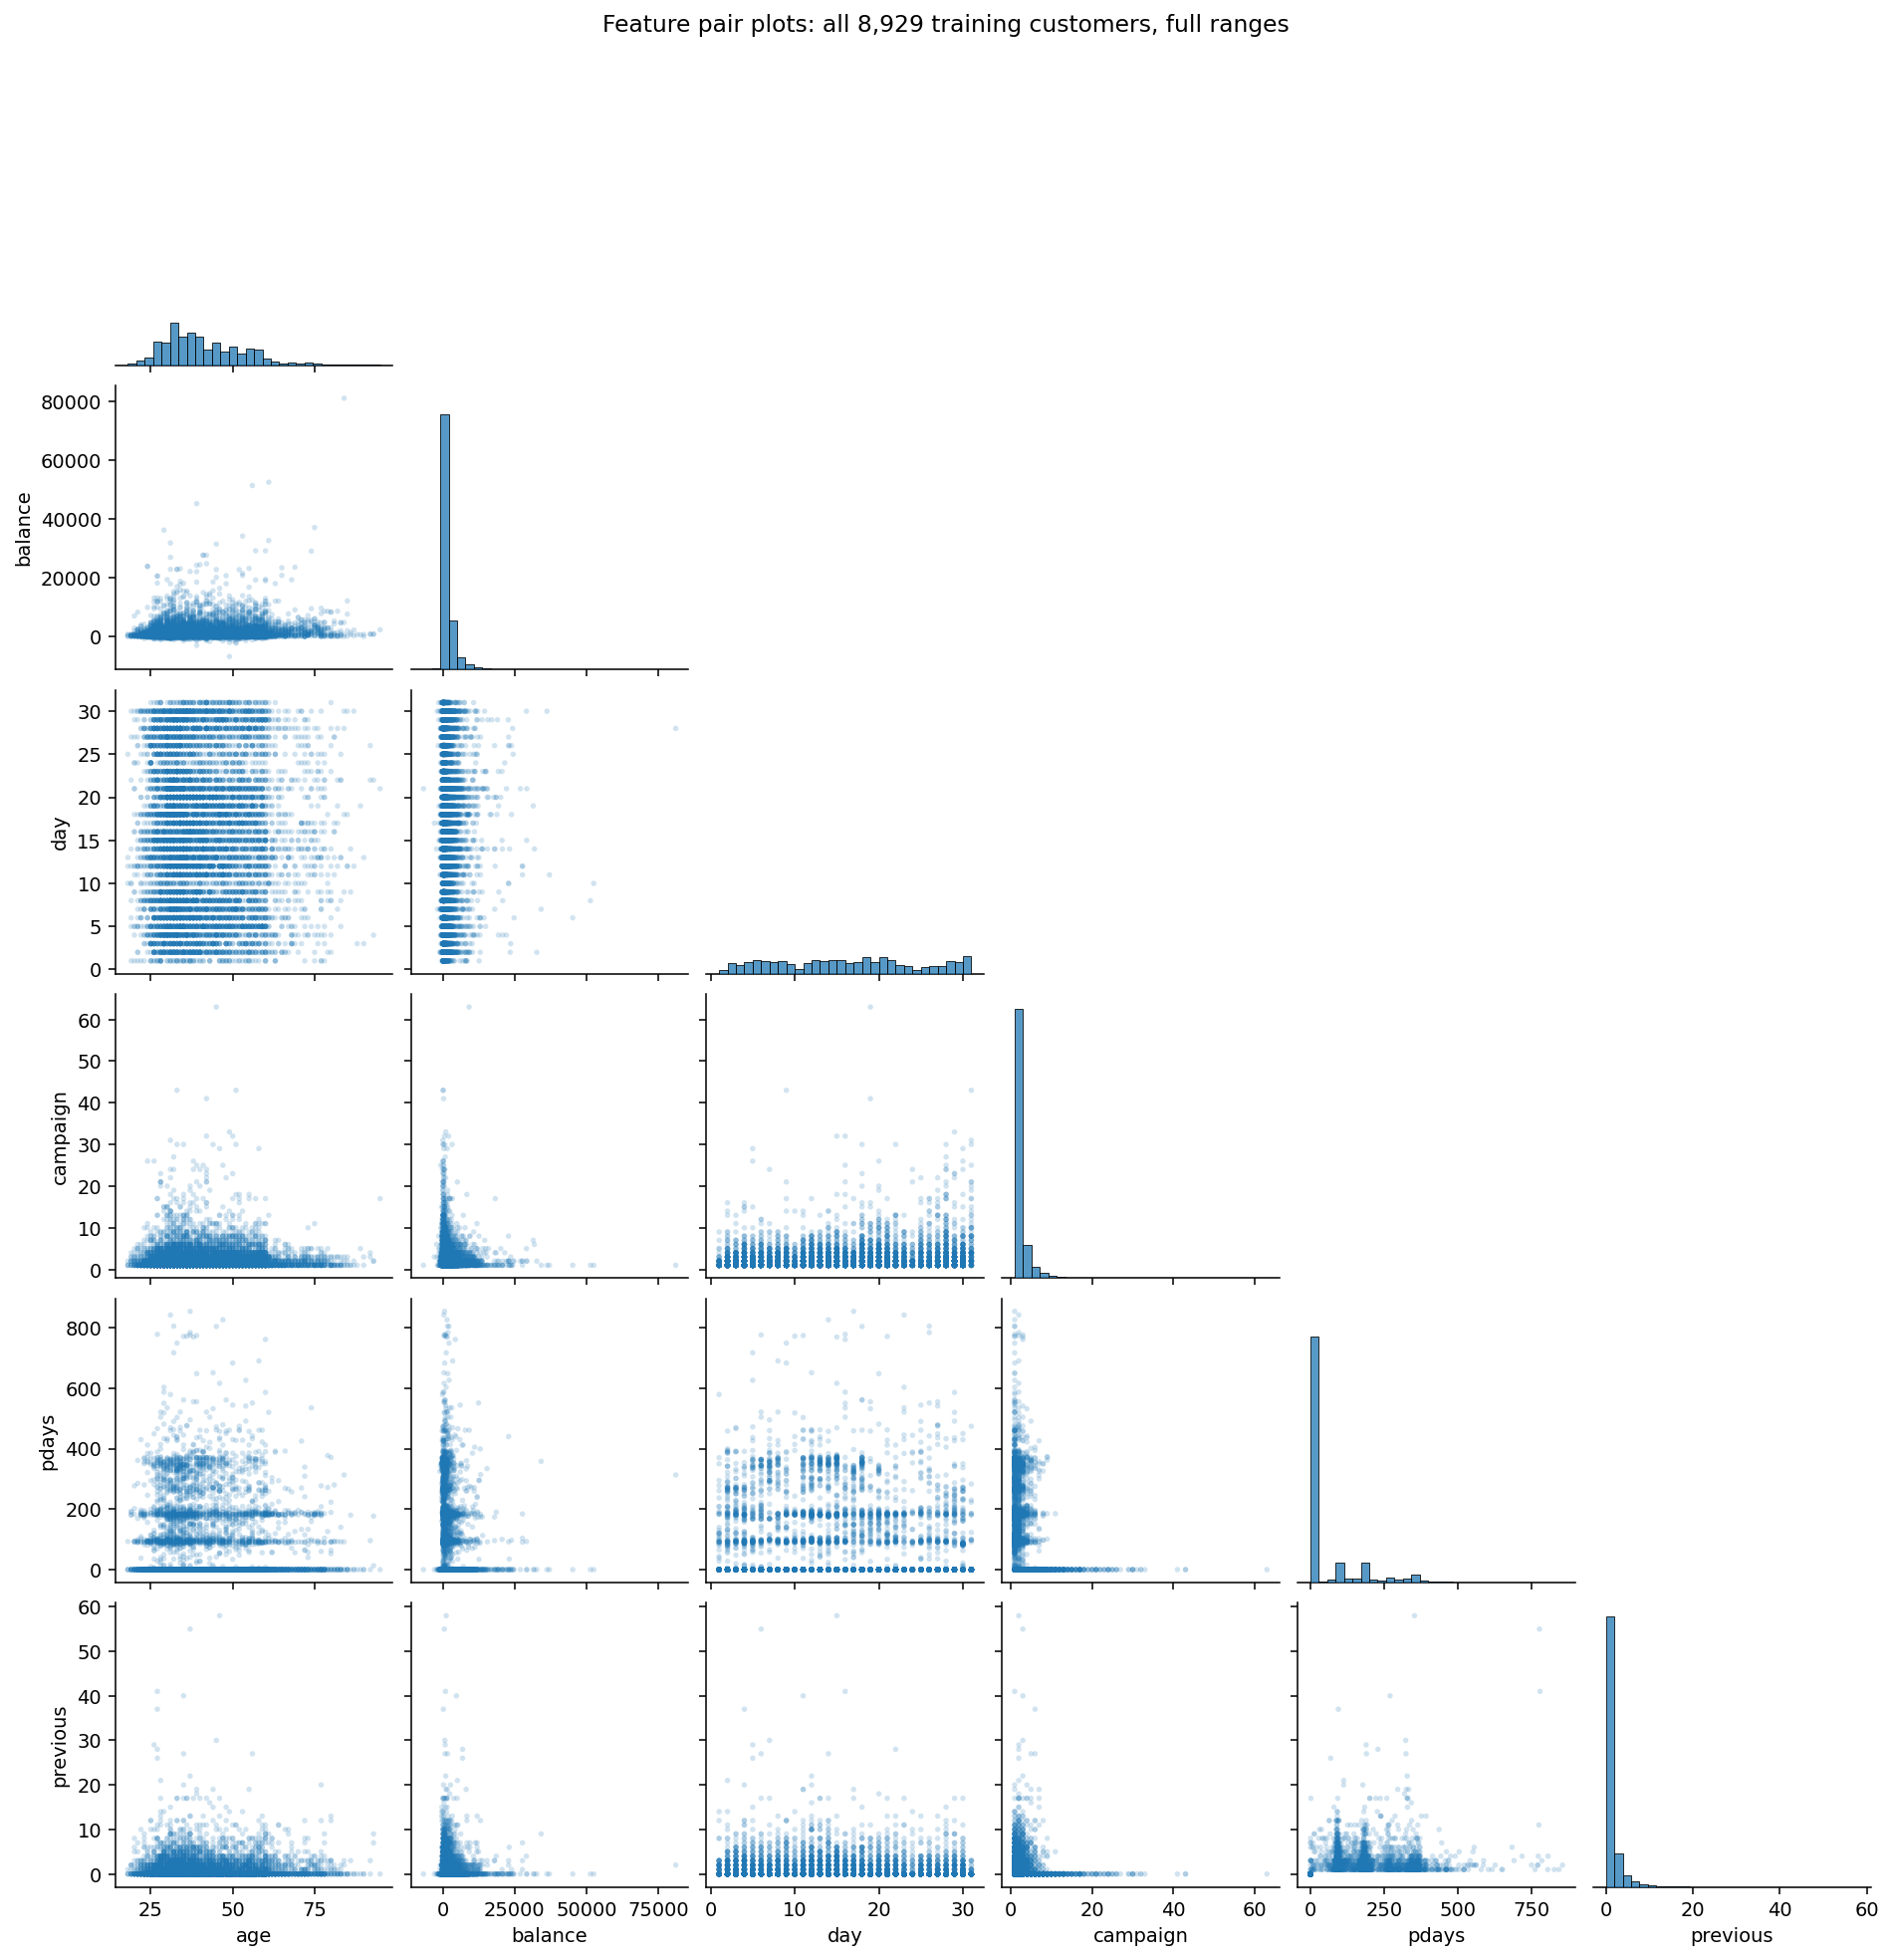

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

cluster_features = ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
pair_grid = sns.pairplot(
    X[cluster_features],
    corner=True,
    diag_kind='hist',
    height=2.3,
    plot_kws={'s': 8, 'alpha': 0.2, 'edgecolor': 'none'},
    diag_kws={'bins': 30},
)
pair_grid.figure.suptitle(
    f'Feature pair plots: all {len(X):,} training customers, full ranges', y=1.02
)
plt.show()


### What the plots show

- No clearly separated customer clusters are visible in these numeric feature pairs at the full-range scales. Age and balance form a broad, overlapping cloud; extreme values are sparse points rather than distinct dense groups.
- The clearest grouping is already explained by contact history: 6,642 training customers have `pdays = 0` and `previous = 0`, while 2,287 have prior contact. The existing `previously_contacted` flag captures this distinction.
- Among previously contacted customers, elapsed-day bands around 90 and 180 days overlap in previous-contact counts. These bands alone do not establish separate customer clusters or explain their cause.
- Stripes in day and contact counts follow their discrete values; they are not sufficient evidence of clusters.

Keep the features and rows unchanged. These feature-only plots do not justify adding cluster labels; they also cannot rule out structure involving more dimensions or categorical features.
